# Report — Hydropower Unit Commitment (Tokke–Vinje)

**Course:** TDT4173 Modern Machine Learning in Practice — Course Project
**Group number:** `[TODO]`
**Kaggle team name:** `[TODO — must include the group number, e.g. "[34] A Fantastic Team"]`

| Full name | Student ID (from student card) |
|-----------|-------------------------------|
| `[TODO]`  | `[TODO]` |
| `[TODO]`  | `[TODO]` |
| `[TODO]`  | `[TODO]` |

Full write-up of our group work. The section titles map directly to the graded items:

| Graded item / skill | Where |
|---|---|
| Domain knowledge, how the data was generated | Section 1 |
| Data manipulation and preparation (time zones, daily → hourly joins, wide → long reshape, topology parsing) | Sections 2.1, 2.4, 3.1 |
| Exploratory data analysis (sanity, single features, pairs/groups, cleanup) | Section 2 |
| Feature engineering (extraction and selection) | Section 3 |
| ≥ 2 predictor types, hyperparameters | Sections 4.2, 4.3 |
| Model ensemble | Section 4.4 |
| Validation strategy | Section 5 |
| Model interpretation (gain importance, SHAP, partial dependence) | Section 6 |

## 0. Executive summary & results

We predict P(ON) for each of the 14 generating units in the Tokke–Vinje system, for every hour of a 168-hour scheduling case (2352 probabilities per case), scored with micro-averaged ROC-AUC. The labels come from the optimiser SHOP, so we treat the task as learning a fast surrogate of SHOP. The problem is modelled as one long table with a row per (case, unit, hour) and a single gradient-boosted classifier.

The most important step was feature engineering from the optimisation problem itself. For every case we solve a **linear relaxation of SHOP's weekly problem** (water balance through the topology, reservoir and discharge limits, end-of-week water values) and give its solution to the model. Without learning, the LP's price-minus-water-cost margin alone reaches AUC 0.956 on the training cases. Adding the LP features to the model raises the time-split validation AUC from 0.960 to 0.989 (Section 3).

| | Short notebook 1 | Short notebook 2 |
|---|---|---|
| Model | LightGBM | XGBoost |
| Features | 81 | 83 (+ two LP features: integer-rounded commitment, robustness to water-value scaling) |
| Time-split validation AUC (last ~15 % of training weeks) | 0.98977 | 0.99092 |
| Public leaderboard | `[TODO]` | `[TODO]` |
| Private leaderboard | `[TODO]` | `[TODO]` |

On identical data, LightGBM and XGBoost are equally good (0.989–0.990), ahead of random forest (0.986) and logistic regression (0.955). A rank-average ensemble of the two adds nothing measurable (+0.00005), because their predictions are almost identical (Spearman ρ = 0.978). Our two selected Kaggle submissions are `[TODO: which two, and why — e.g. NB2 (best validation) and NB1 (different learner)]`.

> **Graders:** this report is **not run** — all outputs below are saved from our actual runs. The cell below sets up the data shared by all later code cells.

In [1]:
# --- Setup shared by every code cell in this report --------------------------
# All experiments below reuse the EXACT feature code of the short notebooks
# (Short notebook 1, Sections 3 + 3b). To compare many models on identical data
# in reasonable time, they run on every 4th training case (731 of 2922 cases,
# all 14 units x 168 hours = 1.72 M rows). Validation uses the same time split
# as the short notebooks: the last ~15 % of Run No (see Section 5).
import gc, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
N_JOBS = 8
MAX_ROUNDS = 1200                       # cap; early stopping picks the actual number
RF_TREES = 200

DATA_DIR = Path("sintef_project/data")
KERNEL, EXTENDED = DATA_DIR / "kernel", DATA_DIR / "extended"
ARTIFACTS = Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
CASE_STEP = 4
CACHE = ARTIFACTS / f"report_long_step{CASE_STEP}.pkl"

uc_meta = pd.read_csv(KERNEL / "Unit_commitment_decisions.csv",
                      usecols=["Run No", "starttime", "total_calculation_time"],
                      parse_dates=["starttime"])

if not CACHE.exists():
    # Rebuild the cached feature table by running Short notebook 1's config,
    # loading, feature-engineering and LP cells verbatim (~10 min), then keep
    # every CASE_STEP-th case.
    import json
    _nb = json.load(open("Short notebook 1.ipynb", encoding="utf-8"))
    _code = ["".join(c["source"]) for c in _nb["cells"] if c["cell_type"] == "code"]
    _G = {}
    for _src in _code[:4]:
        exec(_src, _G)
    _tl = _G["train_long"]
    _tl = _tl[(_tl["Run No"] - 1) % CASE_STEP == 0].copy()
    _tl["start"] = _tl["Run No"].map(uc_meta.set_index("Run No")["starttime"])
    _tl.to_pickle(CACHE)
    del _G, _tl

long = pd.read_pickle(CACHE)

CAT_FEATURES = ["unit_id", "plant_id", "hour_of_day", "dow", "month"]
DROP = ["Run No", "unit", "reservoir", "outlet_res", "target", "start"]
CUT = int(uc_meta["Run No"].quantile(0.85))      # identical to the short notebooks


def add_on_rate_priors(fit_df, *apply_dfs):
    """Historical P(ON) per unit x hour-of-day and unit x month, learned only
    from fit_df (leak-safe). Same function as in the short notebooks."""
    gm = fit_df["target"].mean()
    phd = fit_df.groupby(["unit_id", "hour_of_day"])["target"].mean().rename("onrate_hod")
    pmo = fit_df.groupby(["unit_id", "month"])["target"].mean().rename("onrate_month")
    for d in (fit_df, *apply_dfs):
        d["onrate_hod"] = d.merge(phd, on=["unit_id", "hour_of_day"], how="left")["onrate_hod"].fillna(gm).values
        d["onrate_month"] = d.merge(pmo, on=["unit_id", "month"], how="left")["onrate_month"].fillna(gm).values


tr = long[long["Run No"] <= CUT].copy()
va = long[long["Run No"] > CUT].copy()
add_on_rate_priors(tr, va)
FEATS = [c for c in tr.columns if c not in DROP]
LP_FEATS = [c for c in FEATS if c.startswith("lp_")]
y_tr, y_va = tr["target"].to_numpy(), va["target"].to_numpy()

# Hyperparameters exactly as hard-coded in the short notebooks (n_jobs aside)
LGB_PARAMS = dict(objective="binary", metric="auc", learning_rate=0.05,
                  num_leaves=255, min_child_samples=200, feature_fraction=0.8,
                  bagging_fraction=0.8, bagging_freq=1, max_depth=-1,
                  n_jobs=N_JOBS, verbose=-1, seed=RANDOM_SEED)
XGB_PARAMS = dict(objective="binary:logistic", eval_metric="auc", tree_method="hist",
                  max_depth=8, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=50, reg_lambda=1.0, max_bin=255,
                  n_jobs=N_JOBS, seed=RANDOM_SEED)


def fit_lgb(feats, params=None, train=None, valid=None):
    """Train LightGBM with early stopping (100 rounds) on the validation set.
    Returns (model, validation predictions, validation AUC, seconds)."""
    train = tr if train is None else train
    valid = va if valid is None else valid
    p = {**LGB_PARAMS, **(params or {})}
    cats = [c for c in CAT_FEATURES if c in feats]
    t0 = time.time()
    dtr = lgb.Dataset(train[feats], train["target"], categorical_feature=cats)
    dva = lgb.Dataset(valid[feats], valid["target"], categorical_feature=cats, reference=dtr)
    m = lgb.train(p, dtr, MAX_ROUNDS, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    m.free_dataset()                    # keep only the trees, not the training data (RAM)
    pred = m.predict(valid[feats], num_iteration=m.best_iteration)
    return m, pred, roc_auc_score(valid["target"], pred), time.time() - t0


RESULTS = {}      # model name -> dict(auc, seconds, n_feats, ...) collected for Sections 4 and 7
PREDS = {}        # model name -> validation predictions (for the ensemble)

print(f"Cached feature table: {long.shape[0]:,} rows x {long.shape[1]} columns, "
      f"{long['Run No'].nunique()} cases (every {CASE_STEP}th of {len(uc_meta)})")
print(f"Train: Run No <= {CUT}  -> {tr['Run No'].nunique()} cases, {len(tr):,} rows, "
      f"{tr['start'].min().date()} .. {tr['start'].max().date()}")
print(f"Valid: Run No >  {CUT}  -> {va['Run No'].nunique()} cases, {len(va):,} rows, "
      f"{va['start'].min().date()} .. {va['start'].max().date()}")
print(f"{len(FEATS)} model features ({len(LP_FEATS)} LP features); ON-rate train {y_tr.mean():.3f}, valid {y_va.mean():.3f}")

Cached feature table: 1,719,312 rows x 85 columns, 731 cases (every 4th of 2922)
Train: Run No <= 2483  -> 621 cases, 1,460,592 rows, 2015-01-01 .. 2021-10-16
Valid: Run No >  2483  -> 110 cases, 258,720 rows, 2021-10-20 .. 2022-12-30
81 model features (8 LP features); ON-rate train 0.548, valid 0.355


## 1. Problem understanding & domain knowledge  *(EDA item: domain knowledge / how the data was generated)*

### 1.1 Unit commitment
For each unit and hour, unit commitment decides whether the unit is **ON** (producing at least its minimum stable output `p_min`) or **OFF**. How much a running unit produces is a separate decision. ON/OFF is a real choice and not just "produce zero", for two reasons. First, `p_min` ≈ 34 % of `p_max` for most units (table below). Second, starts and stops cost money and cause wear, so schedules come in continuous blocks. We predict P(ON) for 14 units × 168 hours = 2352 unit-hours per case, scored with micro-averaged ROC-AUC.

### 1.2 How the data was generated
The labels are **not human decisions**. They are optimal schedules from SINTEF's short-term scheduling optimiser **SHOP v17.17.0** on the Tokke–Vinje model, which has 17 reservoirs, 9 plants, 14 units and ≈ 1 GW of capacity. Each case (`Run No`) is one deterministic 168 h optimisation starting at `starttime`, with these inputs:

- **hourly price and inflow**, assumed known for the whole week;
- **initial reservoir volumes** (daily data);
- **water values** at `starttime + 7 days`, i.e. what water left at the end of the week is worth;
- **min-flow and min-volume constraints** (rarely active);
- the **topology**: connections, efficiencies, `p_min`/`p_max`.

A new case starts every day (output below), so consecutive cases overlap by 144 of 168 hours.

The system is a **cascade**: Kjela / Vesle Kjela / Songa → Totak → **Vinje** (3 × 100 MW) → **Tokke** (4 × 107.5 MW) → Bandak → Hogga → out. Byrte → Lio and Haukeli feed in from the side. The two largest plants therefore use water released upstream, so the units are not independent.

In principle the targets are a function of the inputs, so the ML task is to learn a fast **surrogate of SHOP**. There are two caveats. The water values are *synthetic*, and the Hyljelihyl and Vatjern volumes are fixed at 50 % because no records exist, so those two series carry no information.

### 1.3 The economic driver: price vs. water value
The **water value** is the opportunity cost of using water now instead of later. To a first approximation, a unit runs in hour *t* when the price is above the water value of the water it uses. Prices are known for the whole week and water is limited, so SHOP puts production into the **highest-price hours**. The **rank of an hour's price within its week** therefore matters more than its absolute level. Other factors shift this rule:

- **minimum load and start costs** make units run in blocks;
- **storage and inflow** matter: a nearly full reservoir with high inflow is drained even at low prices to avoid spilling, while a nearly empty one saves water;
- **constraints** can force a unit ON or OFF;
- the **cascade** links downstream plants to upstream releases;
- **identical units** (Tokke G1–G4, Vinje G1–G3) are interchangeable, so which of them SHOP picks is partly arbitrary. This puts a ceiling on how well a single unit can be predicted.

The code below extracts these system facts from the raw data.

In [2]:
from pathlib import Path
import yaml
import pandas as pd

DATA_DIR = Path("sintef_project/data")   # same config constant as the short notebooks

topo = yaml.safe_load(open(DATA_DIR / "extended" / "Tokke_Vinje_topology.yaml", encoding="utf-8"))
model, conns = topo["model"], topo["connections"]

# --- Units: capacity limits and where each plant discharges its water ---
outlet = {c["from"]: c["to"] for c in conns if c["from_type"] == "plant"}
units = pd.DataFrame([
    {"unit": g, "plant": g.rsplit("_", 1)[0], "p_min [MW]": v["p_min"], "p_max [MW]": v["p_max"]}
    for g, v in model["generator"].items()
])
units["p_min / p_max"] = (units["p_min [MW]"] / units["p_max [MW]"]).round(2)
units["discharges into"] = units["plant"].map(outlet).fillna("(leaves system)")
display(units.set_index("unit"))
print(f"Plants: {units.plant.nunique()}, units: {len(units)}, "
      f"total installed capacity: {units['p_max [MW]'].sum():.1f} MW")

# --- Reservoirs: size (max_vol) ---
res = (pd.Series({r: v["max_vol"] for r, v in model["reservoir"].items()}, name="max_vol [Mm³]")
         .sort_values(ascending=False))
display(res.to_frame().T)

# --- Case structure: rolling weekly optimisations ---
uc = pd.read_csv(DATA_DIR / "kernel" / "Unit_commitment_decisions.csv",
                 usecols=["Run No", "starttime", "total_calculation_time"], parse_dates=["starttime"])
print(f"Training cases: {len(uc)} (Run No {uc['Run No'].min()}–{uc['Run No'].max()}), "
      f"{uc.starttime.min().date()} → {uc.starttime.max().date()}")
print("Days between consecutive case starts:", uc.starttime.diff().dt.days.value_counts().to_dict())
print("Each case = 168 h → consecutive cases overlap by 144 h (6 of 7 days)")
print("SHOP solve time per case [s]:",
      uc.total_calculation_time.describe()[["mean", "min", "max"]].round(1).to_dict())

,plant,p_min [MW],p_max [MW],p_min / p_max,discharges into
unit,,,,,
Hogga_G1,Hogga,3.0,17.0,0.18,(leaves system)
Tokke_G1,Tokke,36.9,107.5,0.34,Bandak
Tokke_G2,Tokke,36.9,107.5,0.34,Bandak
Tokke_G3,Tokke,36.9,107.5,0.34,Bandak
Tokke_G4,Tokke,36.9,107.5,0.34,Bandak
Lio_G1,Lio,14.8,43.0,0.34,r_Vest_Vassdraget
Byrte_G1,Byrte,6.9,20.0,0.34,Byrtevatn
Vinje_G1,Vinje,34.4,100.0,0.34,Vinjevatn
Vinje_G2,Vinje,34.4,100.0,0.34,Vinjevatn


Plants: 9, units: 14, total installed capacity: 1003.4 MW


,Songavatn,Totak,Bordalsvatn,Bandak,Foersvatn,Bitdalsvatn,Kjelavatn,Langesae,Byrtevatn,Botnedalsvatn,Staavatn,Langeidvatn,Vaamarvatn,Venemo,Vinjevatn,Vatjern,Hyljelihyl
max_vol [Mm³],640.0,257.8,184.2,174.2,122.3,110.0,84.5,78.0,76.71,54.17,48.0,32.1,26.2,23.0,9.36,0.3,0.26


Training cases: 2922 (Run No 1–2922), 2015-01-01 → 2022-12-31
Days between consecutive case starts: {1.0: 2921}
Each case = 168 h → consecutive cases overlap by 144 h (6 of 7 days)
SHOP solve time per case [s]: {'mean': 147.0, 'min': 22.4, 'max': 4525.7}


### 1.4 Hypotheses for later sections

| # | Hypothesis | Checked in |
|---|---|---|
| H1 | P(ON) rises with the **within-week price rank** | EDA 2.3, PDP (Sec. 6) |
| H2 | **Price − water value** is predictive | EDA 2.3, importance (Sec. 6) |
| H3 | High **fill fraction / inflow** raise ON-rates (spill avoidance) | EDA 2.3 |
| H4 | Strong **hour-of-day** and **seasonal** patterns | EDA 2.2 |
| H5 | Units at the same plant are **co-activated**; identical units may differ in ON-rate | EDA 2.3 |
| H6 | Overlapping cases make **random K-fold leak**, so we use a **time-based split** | Sec. 5 |

**Pipeline consequences:** use *relative* price features (rank and deviation within the case), use static topology (capacity, plant, cascade position) as unit features, and drop the constant Hyljelihyl/Vatjern volume columns.

## 2. Exploratory Data Analysis  *(covers ≥4 EDA items → avoids −3)*

The code and saved output for this section follow directly after the text. Figures are referred to in order (Fig. 2.1–2.4).

### 2.1 Data sanity
All time series are stamped in **UTC**. The hourly series are price, inflow and the two constraint files. The daily series (volume and water value) are stamped at 00:00 UTC, and every case starts at 00:00 UTC. A case's 168 hours can therefore be joined to the hourly data with `starttime + hour`, and to the daily data by date, without time-zone shifts.

- **No missing values and no duplicate timestamps** in any table, and every UC target is 0 or 1.
- The hourly series are regular, with one exception: from October 2025 the price file switches to **15-minute resolution** (the 8839 "irregular steps" in the table). This is after the last test case, so it does not affect us.
- The data covers the whole test period: the last test case starts on 2024-12-25 and needs prices up to 2024-12-31 23:00 and the water value for 2025-01-01.
- The volumes of **Hyljelihyl and Vatjern** are exactly 50 % of `max_vol` on every day (standard deviation 0), which confirms the dataset note that they are filled-in values and not measurements.

### 2.2 Individual features and the target
- **Price (Fig. 2.1, left).** Prices are low and stable in 2015–2020 (yearly mean 9–43 EUR/MWh), rise sharply in 2021–2022 during the energy crisis (2022 mean 211 EUR/MWh, standard deviation 126), and are lower again in the 2023–2024 test period (79 and 50 EUR/MWh). The test distribution is therefore unlike the most recent training year, which is one reason we use *relative* price features (Section 3).
- **Target (Fig. 2.1, right).** The overall ON-rate is **0.516**, so the classes are balanced overall, but ON-rates differ a lot between units: from 0.75 (Lio) to 0.26 (Vinje G3). Identical units are not used equally (Tokke G1 0.67 vs. G2 0.48; Vinje G1 0.48 vs. G3 0.26), so SHOP has a systematic preference among them, which a unit-id feature can learn.
- **Hour of day and season (Fig. 2.2).** The seasonal pattern is strong: Tokke runs most in May (spring flood), Lio in February–March and September–October, while Vinje G3 is rarely on in May–August. The hour-of-day pattern is weak: the large units are only slightly more often ON during the day. H4 therefore holds for season but only weakly for hour of day. This fits Section 1.3: what matters is an hour's price *relative to the rest of the week*, not the clock time.
- **Schedules come in blocks.** A unit switches only 0.5 (Haukeli) to 3.6 (Vinje G3) times per week on average. Between 4 % and 58 % of unit-weeks are ON for all 168 hours, and between 9 % and 42 % are OFF throughout (table in the output). This matches the minimum load and start costs described in Section 1.

### 2.3 Pairs and groups of features
- **Price vs commitment (H1, Fig. 2.3 left).** For every plant the ON-rate rises monotonically with the decile of the hour's price within its week, e.g. Vinje from 0.21 in the cheapest decile to 0.56 in the most expensive, and Tokke from 0.40 to 0.72. **H1 confirmed.**
- **Price vs water value (H2, Fig. 2.3 middle).** The ON-rate rises steeply around a spread of zero between price and the unit's net water value, from about 0.15–0.30 for clearly negative spreads to about 0.5 at zero and 0.6 for spreads of +50 EUR/MWh. It falls again for the most extreme spreads (> 100 EUR/MWh): 89 % of those hours are from the 2021–2022 crisis, where the ON-rate at such spreads was only 0.40–0.51, against 0.86–1.00 in earlier years. A single static spread does not capture the whole decision there. **H2 confirmed** for the bulk of the data.
- **Reservoir state (H3, Fig. 2.3 right).** The ON-rate rises from 0.19 for the emptiest 5 % of intake-reservoir states to 0.91 for the fullest, and weekly inflow raises it in the top quantiles (to 0.76). Full reservoirs are drained to avoid spill. **H3 confirmed.**
- **Reservoir correlation.** Water values are strongly correlated across reservoirs (mean pairwise ρ = 0.88), since they come from the same market outlook; fill fractions much less so (ρ = 0.48). We therefore add system means of water value and fill fraction rather than all 17 series.
- **Co-activation (H5, Fig. 2.4 left).** Units at the same plant have a mean ON/OFF correlation of 0.77, against 0.30 for all other pairs. Tokke and Vinje are also strongly correlated with each other, because Tokke uses water released by Vinje (cascade). Lio and Kjela are nearly independent of the rest. **H5 confirmed.**
- **Overlapping cases (H6, Fig. 2.4 right).** For the same calendar hour, two consecutive cases give different labels for 12.2 % of unit-hours. The disagreement is spread almost evenly over the horizon (11.7–13.4 %), rising only slightly in the last hours of the earlier case. So adding a new day of prices and inflows shifts the whole week's schedule, not only its end. Neighbouring cases still share most inputs and 88 % of labels, so random K-fold would leak (Section 5).

### 2.4 Feature cleanup
- **Time zones:** the UTC offset is removed from every timestamp, and the daily series are normalised to midnight before joining.
- **Daily → hourly:** daily data is joined with an as-of lookup: volume and water value at the case start date, and water value at start + 7 days for the end of the week.
- **Constant series:** the Hyljelihyl and Vatjern volumes are constant and carry no information.
- **Constraints:** the min-volume constraints are non-zero in 13 % (Byrtevatn), 26 % (Staavatn) and 34 % (Totak) of hours, and the min-flow series take only 2–31 distinct values. The Kjelavatn and Hyljelihyl min-flow series are identical (ρ = 1). All are kept as raw hourly columns; redundancy is handled by the filters in Section 3.3.

2.1 Raw tables (all timestamps UTC):


,rows,first,last,step,irregular steps,missing values,duplicate timestamps
price (h),103062,2015-01-01 00:00,2025-12-31 23:45,0 days 01:00:00,8839,0,0
inflow (h),594224,1958-01-01 00:00,2025-10-15 07:00,0 days 01:00:00,0,0,0
volume (d),3654,2015-01-01 00:00,2025-01-01 00:00,1 days 00:00:00,0,0,0
water value (d),3654,2015-01-01 00:00,2025-01-01 00:00,1 days 00:00:00,0,0,0
min flow (h),96432,2015-01-01 00:00,2025-12-31 23:00,0 days 01:00:00,0,0,0
min volume (h),96432,2015-01-01 00:00,2025-12-31 23:00,0 days 01:00:00,0,0,0


UC decisions: 2922 cases x 2352 targets, missing targets: 0, non-binary targets: 0
Fill fraction of Hyljelihyl / Vatjern (filled-in series):
       Hyljelihyl  Vatjern
mean         0.5      0.5
std          0.0      0.0
min          0.5      0.5
max          0.5      0.5


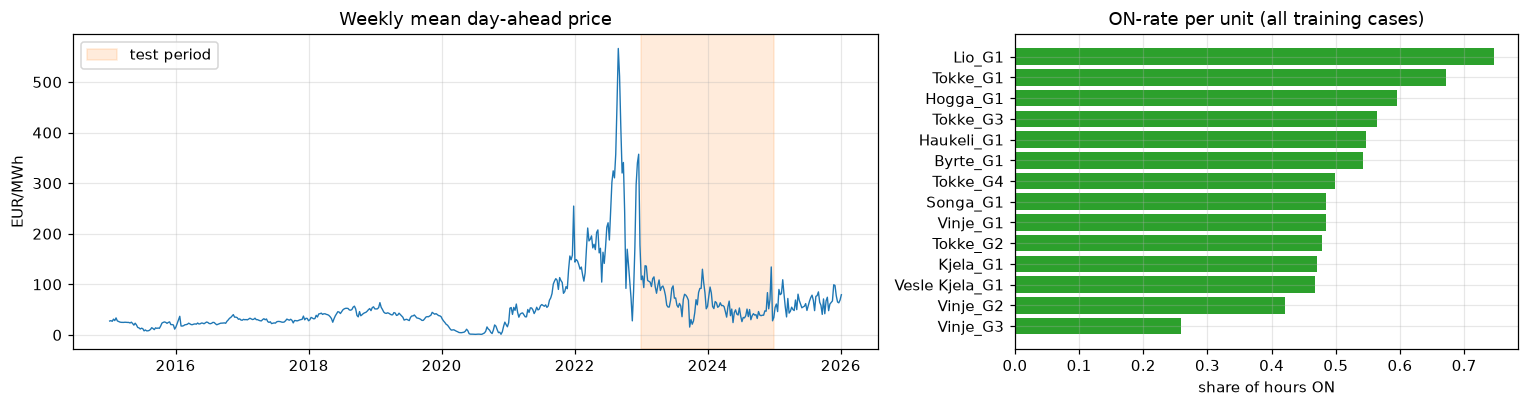

Overall ON-rate: 0.516
Price by year (EUR/MWh):
 y     2015  2016  2017  2018  2019  2020  2021   2022  2023  2024  2025
mean  19.8  25.2  28.8  43.3  39.3   9.3  75.1  211.3  79.4  50.1  67.2
std    7.7   6.6   4.6   9.4   8.2   8.3  47.2  125.8  36.3  34.2  31.2


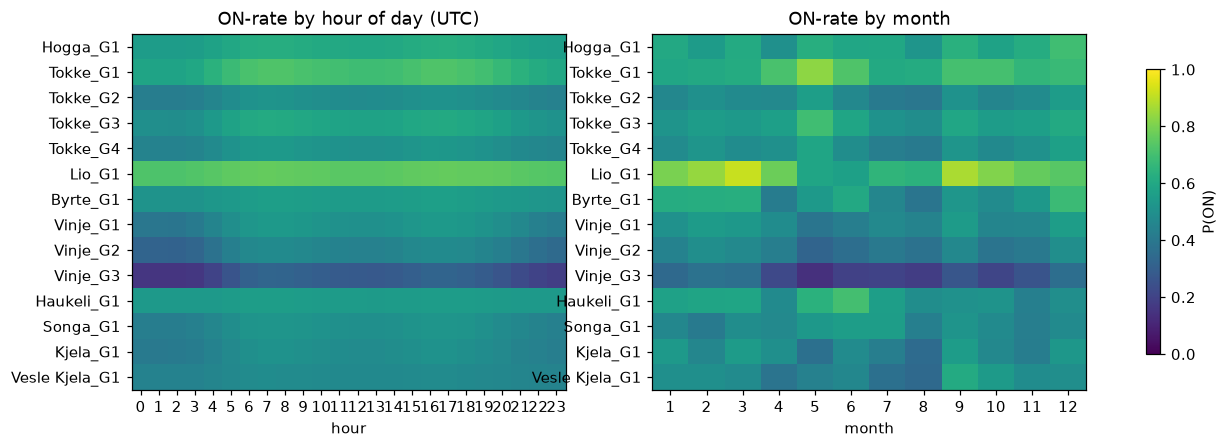

Block structure of the schedules (168 h per case):


,Hogga_G1,Tokke_G1,Tokke_G2,Tokke_G3,Tokke_G4,Lio_G1,Byrte_G1,Vinje_G1,Vinje_G2,Vinje_G3,Haukeli_G1,Songa_G1,Kjela_G1,Vesle Kjela_G1
mean switches / week,1.72,3.02,1.96,2.51,2.12,1.17,0.99,3.02,3.32,3.60,0.49,2.03,2.33,0.75
share weeks always ON,0.39,0.40,0.31,0.35,0.32,0.58,0.42,0.16,0.10,0.04,0.49,0.29,0.26,0.36
share weeks always OFF,0.18,0.09,0.29,0.19,0.26,0.12,0.32,0.28,0.32,0.42,0.33,0.30,0.29,0.39


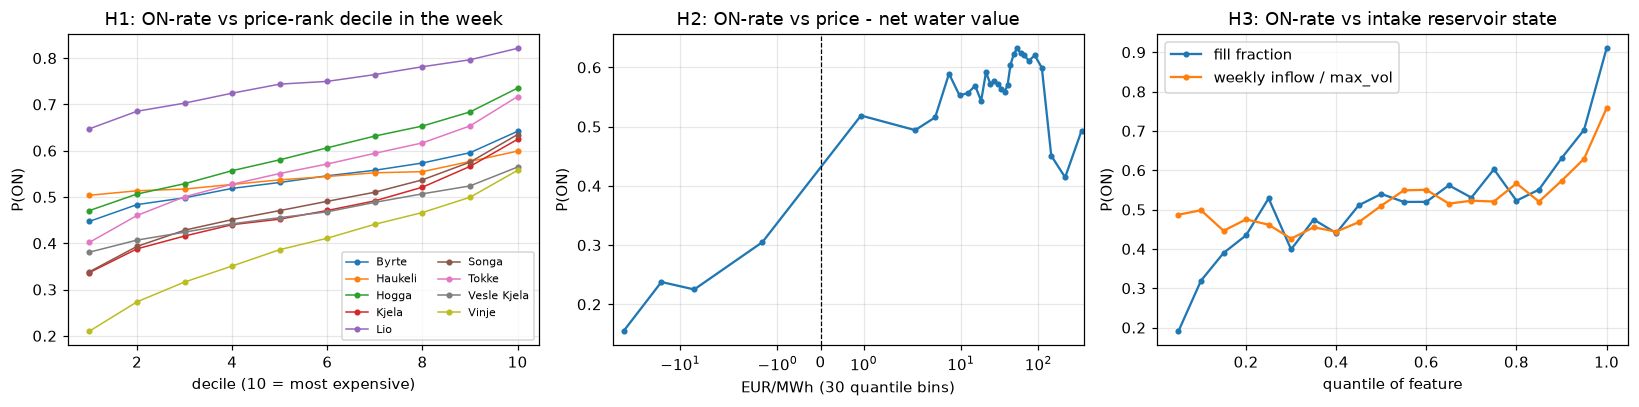

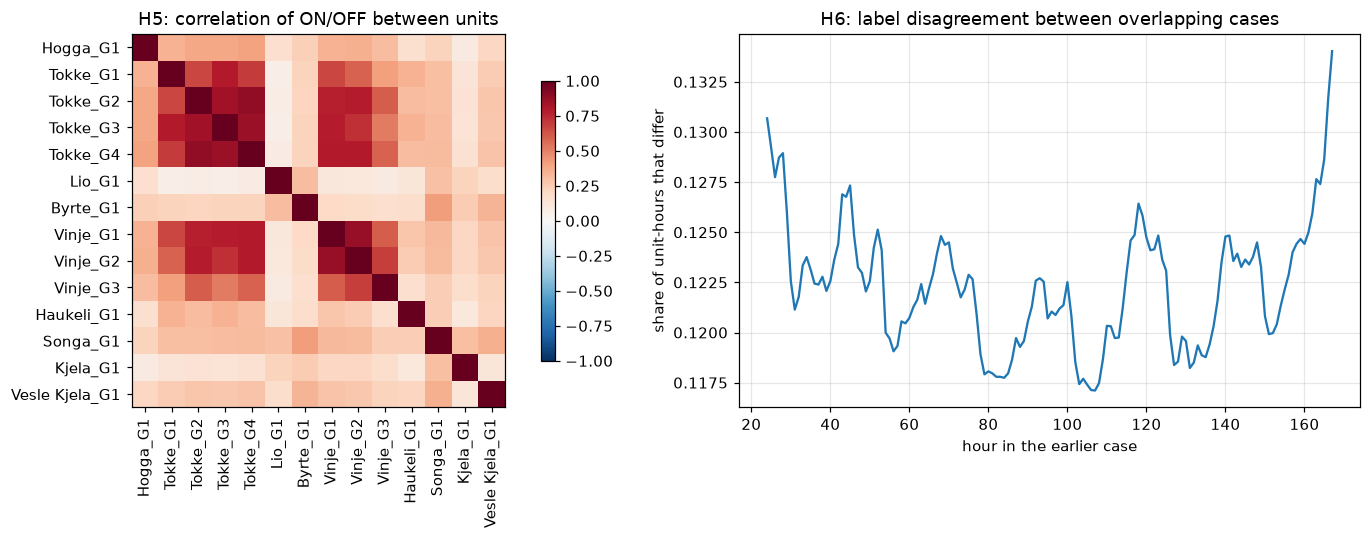

Overlapping cases: mean disagreement 0.122; hours 24-47: 0.125, last 24 h of the earlier case: 0.124
Mean ON/OFF correlation, units at the same plant: 0.77; all other pairs: 0.30
Mean pairwise correlation across reservoirs: water value 0.88, fill fraction 0.48
Constraint series (hourly, 2015-2025):


,distinct values,share at most common value,share non-zero
minflow_b_Kjelavatn,31,0.584,1.000
minflow_b_Hyljelihyl,31,0.584,1.000
minflow_b_Vinjevatn,2,0.581,1.000
minflow_b_Byrtevatn,2,0.661,0.339
minflow_b_Bandak,2,0.581,1.000
minflow_r_Vest_Vassdraget,3,0.581,1.000
minvol_Totak,3,0.661,0.339
minvol_Byrtevatn,2,0.874,0.126
minvol_Staavatn,2,0.745,0.255


In [3]:
# --- Section 2: Exploratory data analysis ------------------------------------
import yaml
price   = pd.read_csv(KERNEL / "Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"])
inflow  = pd.read_csv(KERNEL / "Historical_inflow_1958_2025.csv", parse_dates=["date"])
volume  = pd.read_csv(KERNEL / "Historical_volume_2015_2024.csv", parse_dates=["date"])
wvalue  = pd.read_csv(KERNEL / "Synthetic_water_value_2015_2024.csv", parse_dates=["date"])
minflow = pd.read_csv(EXTENDED / "Constraint_min_flow.csv", parse_dates=["date"])
minvol  = pd.read_csv(EXTENDED / "Constraint_min_volume.csv", parse_dates=["date"])
uc_full = pd.read_csv(KERNEL / "Unit_commitment_decisions.csv", parse_dates=["starttime"])
topo = yaml.safe_load(open(EXTENDED / "Tokke_Vinje_topology.yaml", encoding="utf-8"))["model"]
max_vol = pd.Series({r: v["max_vol"] for r, v in topo["reservoir"].items()})

# ---------------------------------------------------------------- 2.1 sanity
tables = {"price (h)": price, "inflow (h)": inflow, "volume (d)": volume, "water value (d)": wvalue,
          "min flow (h)": minflow, "min volume (h)": minvol}
sanity = pd.DataFrame({
    name: {"rows": len(d), "first": d["date"].min().strftime("%Y-%m-%d %H:%M"),
           "last": d["date"].max().strftime("%Y-%m-%d %H:%M"),
           "step": str(d["date"].diff().mode()[0]),
           "irregular steps": int((d["date"].diff().dropna() != d["date"].diff().mode()[0]).sum()),
           "missing values": int(d.drop(columns="date").isna().sum().sum()),
           "duplicate timestamps": int(d["date"].duplicated().sum())}
    for name, d in tables.items()}).T
TARGET_ALL = [c for c in uc_full.columns if c.startswith("result_committed_")]
print("2.1 Raw tables (all timestamps UTC):")
display(sanity)
print(f"UC decisions: {len(uc_full)} cases x {len(TARGET_ALL)} targets, "
      f"missing targets: {int(uc_full[TARGET_ALL].isna().sum().sum())}, "
      f"non-binary targets: {int((~uc_full[TARGET_ALL].isin([0, 1])).sum().sum())}")
_fill = volume.set_index("date")[["Hyljelihyl", "Vatjern"]] / max_vol[["Hyljelihyl", "Vatjern"]]
print("Fill fraction of Hyljelihyl / Vatjern (filled-in series):\n",
      _fill.describe().loc[["mean", "std", "min", "max"]].round(3).to_string())

# Wide targets -> array (case, unit, hour)
UNITS_ALL = list(dict.fromkeys(c.rsplit("_t", 1)[0].replace("result_committed_", "") for c in TARGET_ALL))
Y = uc_full[TARGET_ALL].to_numpy(dtype="int8").reshape(len(uc_full), len(UNITS_ALL), 168)
PLANT = {u: u.rsplit("_G", 1)[0] for u in UNITS_ALL}

# ---------------------------------------------------------------- 2.2 single features + target
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
wk = price.set_index("date")["Day-ahead price (EUR/MWh)"].resample("W").mean()
ax[0].plot(wk.index, wk.values, lw=0.9)
ax[0].axvspan(pd.Timestamp("2023-01-01", tz="UTC"), pd.Timestamp("2024-12-31", tz="UTC"),
              color="tab:orange", alpha=0.15, label="test period")
ax[0].set(title="Weekly mean day-ahead price", ylabel="EUR/MWh"); ax[0].legend()
onrate_unit = pd.Series(Y.mean(axis=(0, 2)), index=UNITS_ALL).sort_values()
ax[1].barh(onrate_unit.index, onrate_unit.values, color="tab:green")
ax[1].set(title="ON-rate per unit (all training cases)", xlabel="share of hours ON")
plt.tight_layout(); plt.show()
print(f"Overall ON-rate: {Y.mean():.3f}")
_yr = price.assign(y=price["date"].dt.year).groupby("y")["Day-ahead price (EUR/MWh)"].agg(["mean", "std"]).round(1)
print("Price by year (EUR/MWh):\n", _yr.T.to_string())

hod = np.arange(168) % 24                                       # every case starts 00:00 UTC
month = np.array([(uc_full["starttime"] + pd.to_timedelta(t, "h")).dt.month.to_numpy() for t in range(168)]).T
hm_hod = pd.DataFrame({h: Y[:, :, hod == h].mean(axis=(0, 2)) for h in range(24)}, index=UNITS_ALL)
hm_mon = pd.DataFrame({m: np.array([Y[:, j, :][month == m].mean() for j in range(len(UNITS_ALL))])
                       for m in range(1, 13)}, index=UNITS_ALL)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, hm, title, xl in [(ax[0], hm_hod, "ON-rate by hour of day (UTC)", "hour"),
                         (ax[1], hm_mon, "ON-rate by month", "month")]:
    im = a.imshow(hm.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    a.set_yticks(range(len(UNITS_ALL)), UNITS_ALL); a.set_xticks(range(hm.shape[1]), hm.columns)
    a.set(title=title, xlabel=xl); a.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="P(ON)"); plt.show()

sw = np.abs(np.diff(Y, axis=2)).sum(axis=2)                     # switches per unit-week
blocks = pd.DataFrame({"mean switches / week": sw.mean(axis=0),
                       "share weeks always ON": (Y.min(axis=2) == 1).mean(axis=0),
                       "share weeks always OFF": (Y.max(axis=2) == 0).mean(axis=0)},
                      index=UNITS_ALL).round(2)
print("Block structure of the schedules (168 h per case):")
display(blocks.T)

# ---------------------------------------------------------------- 2.3 pairs / groups
long["plant"] = long["unit"].str.rsplit("_G", n=1).str[0]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
dec = (long["price_rank"] * 10).clip(upper=9.999).astype(int) + 1
pv = long.assign(decile=dec).pivot_table(index="decile", columns="plant", values="target")
pv.plot(ax=ax[0], marker="o", ms=3, lw=1)
ax[0].set(title="H1: ON-rate vs price-rank decile in the week", xlabel="decile (10 = most expensive)",
          ylabel="P(ON)"); ax[0].legend(fontsize=7, ncol=2)
q = pd.qcut(long["pwv_spread_net"], 30, duplicates="drop")
g = long.groupby(q, observed=True).agg(x=("pwv_spread_net", "median"), y=("target", "mean"))
ax[1].plot(g["x"], g["y"], marker="o", ms=3); ax[1].axvline(0, color="k", lw=0.8, ls="--")
ax[1].set(title="H2: ON-rate vs price - net water value", xlabel="EUR/MWh (30 quantile bins)",
          xscale="symlog", ylabel="P(ON)")
for col, lab in [("fill_frac", "fill fraction"), ("inflow_wk_frac", "weekly inflow / max_vol")]:
    qq = pd.qcut(long[col], 20, duplicates="drop")
    gg = long.groupby(qq, observed=True).agg(x=(col, "median"), y=("target", "mean"))
    ax[2].plot(gg["x"].rank(pct=True), gg["y"], marker="o", ms=3, label=lab)
ax[2].set(title="H3: ON-rate vs intake reservoir state", xlabel="quantile of feature", ylabel="P(ON)")
ax[2].legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.15, 1]})
corr_units = pd.DataFrame(Y.transpose(0, 2, 1).reshape(-1, len(UNITS_ALL)), columns=UNITS_ALL).corr()
im = ax[0].imshow(corr_units.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(UNITS_ALL)), UNITS_ALL, rotation=90); ax[0].set_yticks(range(len(UNITS_ALL)), UNITS_ALL)
ax[0].set_title("H5: correlation of ON/OFF between units"); ax[0].grid(False)
fig.colorbar(im, ax=ax[0], shrink=0.75)
# H6: the same calendar hour in two consecutive cases (case r hour t == case r+1 hour t-24)
consec = (uc_full["starttime"].diff().dt.days == 1).to_numpy()[1:]
dis = (Y[:-1, :, 24:] != Y[1:, :, :-24])[consec].mean(axis=(0, 1))
ax[1].plot(np.arange(24, 168), dis)
ax[1].set(title="H6: label disagreement between overlapping cases",
          xlabel="hour in the earlier case", ylabel="share of unit-hours that differ")
plt.tight_layout(); plt.show()
print(f"Overlapping cases: mean disagreement {dis.mean():.3f}; hours 24-47: {dis[:24].mean():.3f}, "
      f"last 24 h of the earlier case: {dis[-24:].mean():.3f}")

_same = [(a, b) for i, a in enumerate(UNITS_ALL) for b in UNITS_ALL[i + 1:] if PLANT[a] == PLANT[b]]
print(f"Mean ON/OFF correlation, units at the same plant: {np.mean([corr_units.loc[a, b] for a, b in _same]):.2f}; "
      f"all other pairs: {(corr_units.values[np.triu_indices(len(UNITS_ALL), 1)].sum() - sum(corr_units.loc[a, b] for a, b in _same)) / (len(UNITS_ALL)*(len(UNITS_ALL)-1)/2 - len(_same)):.2f}")
const_res = ["Hyljelihyl", "Vatjern"]
_wv = wvalue.drop(columns="date"); _ff = (volume.drop(columns=["date"] + const_res) / max_vol.drop(const_res))
_off = lambda c: c.values[np.triu_indices(len(c), 1)].mean()
print(f"Mean pairwise correlation across reservoirs: water value {_off(_wv.corr()):.2f}, "
      f"fill fraction {_off(_ff.corr()):.2f}")

# ---------------------------------------------------------------- 2.4 cleanup: near-constant constraints
cons = pd.concat([minflow.drop(columns="date").add_prefix("minflow_"),
                  minvol.drop(columns="date").add_prefix("minvol_")], axis=1)
cons_tab = pd.DataFrame({"distinct values": cons.nunique(),
                         "share at most common value": cons.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
                         "share non-zero": (cons != 0).mean()}).round(3)
print("Constraint series (hourly, 2015-2025):")
display(cons_tab)

## 3. Feature Engineering  *(avoids −3)*

*Feature code: Short notebook 1, Sections 3 and 3b (Short notebook 2 uses the same code plus two LP features). Selection experiments: code cell after this section.*

### 3.1 Framing
We model a **long table** with one row per (case, unit, hour) and the target ON/OFF. That gives 2922 × 14 × 168 ≈ **6.9 M training rows** and 1.7 M test rows. One binary classifier predicts P(ON) for every row, which matches the micro-averaged ROC-AUC metric directly. The wide submission is unit-major (unit 0 hours 0–167, unit 1 hours 0–167, …), so the reshape is a plain reshape of each case's 2352 values, and predictions are pivoted back to the wide format at the end. Static unit information (capacity, start cost, intake and outlet reservoir) is parsed from the topology YAML: the intake reservoir of each plant is found by walking upstream through tunnels in the `connections` graph, and the outlet reservoir by following its discharge downstream.

### 3.2 Feature extraction
The feature groups are chosen from the domain analysis in Sections 1–2, for 81 features in total:

| Group | Examples | Why |
|---|---|---|
| Unit & topology | unit/plant id, `p_min`, `p_max`, start cost, units at plant, intake/outlet reservoir | units differ in size, cascade position and preference order (2.2) |
| Calendar | hour of day, weekday, month, cyclic sin/cos, hour in horizon | seasonal patterns (H4), end-of-horizon effect |
| Relative price | rank of the hour's price in the week and in the day, deviation and z-score vs week mean, lags/leads, forward 3/6/12 h mean and max | SHOP knows all prices of the week and fills the most expensive hours first (H1) |
| Water value & storage | price − water value (start, end, *net* = intake minus outlet value), price/water-value ratio, fill fraction, weekly inflow relative to reservoir size, margin to min volume, downstream reservoir state, system means | the economic rule and spill avoidance (H2, H3) |
| "In the money" | share of the week's hours with price > water value, and how far the hour's rank lies above that cut-off | turns the rule into an estimate of how many hours the unit should run |
| Constraints | hourly min-flow / min-volume per restricted river/reservoir | can force units ON |
| ON-rate priors | historical P(ON) per unit × hour-of-day and unit × month, computed on the training fold only | strong baseline, leak-free |
| **LP features (simplified SHOP)** | for each case, solve a linear relaxation of SHOP's weekly problem (water balance through the topology, reservoir and discharge limits, constraints, end-of-week water values) and use its plant discharge, the unit's implied load and the price minus the LP's marginal water cost | lets the model see the optimiser's own trade-off |

The LP features are the most important extraction step. **Used alone as a score, without any learning, the LP margin already gives ROC-AUC 0.956 on all training cases (0.960 on our validation cases).** The LP leaves out the ON/OFF integers, start costs, `p_min` and head variation; the gradient-boosting model learns to correct for those. Short notebook 2 adds two features aimed at exactly that gap: a `p_min`-aware integer rounding of the LP solution (`lp_commit_hat`, AUC 0.899 alone) and the share of three LP solves, with end-of-week water values scaled by 0.9 / 1.0 / 1.1, in which the plant is economic (`lp_run_frac`), which flags the marginal hours.

### 3.3 Feature selection
All variants below use LightGBM with the short-notebook hyperparameters on the same time split (output after this section).

- **Near-constant filter** (most common value in > 99 % of training rows): only `minvol_start` (99.1 %).
- **Correlation filter** (|ρ| > 0.98, keeping the first feature of each group): drops 14 features, e.g. `p_max`/`p_nom` (duplicates of `p_min`), `hour_in_horizon` (identical to `hour`), the short price lags/leads and forward means (duplicates of `price`), the identical Hyljelihyl min-flow series, and the smoothed/lagged LP margins.
- **Effect:** the filtered set (66 features) scores 0.98910 against 0.98919 with all 81, so the removed features carried no extra information but did not hurt either. Tree models are robust to redundant inputs, so we kept the full set in the short notebooks. The filtered set trained in 55 s instead of 85 s and would be the choice if runtime mattered.

| Variant | Features | Validation AUC |
|---|---|---|
| All features (as in Short notebook 1) | 81 | **0.98919** |
| After near-constant + correlation filter | 66 | 0.98910 |
| Without LP features | 73 | 0.95996 |
| LP features + unit/plant/hour only | 11 | 0.98525 |

- **Effect of the LP features.** Removing the 8 LP features drops the AUC from 0.989 to 0.960. With only the LP features plus unit, plant and hour, 11 features in total, the model reaches 0.985. This is by far the largest single effect of any feature group.
- **Group ablation (before the LP features).** With LightGBM on three rolling yearly folds (validation years 2020, 2021, 2022, each with a 7-day purge gap, every 4th case), we tested adding and removing feature groups:

| Variant | 2020 | 2021 | 2022 | Mean |
|---|---|---|---|---|
| Baseline (73 features) | 0.9406 | 0.9488 | 0.9614 | 0.9503 |
| + water-budget features | 0.9452 | 0.9483 | 0.9612 | 0.9516 |
| − static unit features | 0.9450 | 0.9452 | 0.9632 | 0.9511 |
| − absolute price | 0.9441 | 0.9462 | 0.9623 | 0.9509 |
| + all 22 candidate features | 0.9419 | 0.9488 | 0.9611 | 0.9506 |

Repeating runs with three seeds changed the 2020 score by up to ±0.003, so none of these differences is larger than seed noise. We therefore did **not** add the candidate groups (end-of-week volume, daily release, block features, unit order), which keeps the feature set smaller.

In [4]:
# --- Section 3: feature selection ---------------------------------------------
# (1) near-constant filter, (2) correlation filter, (3) group ablation of the LP
# features. All variants are scored with LightGBM (short-notebook hyperparameters)
# on the time split from the setup cell.
num_feats = [c for c in FEATS if c not in CAT_FEATURES]

# (1) near-constant: the most common value covers > 99 % of training rows
top_share = pd.Series({c: tr[c].value_counts(normalize=True, dropna=False).iloc[0] for c in num_feats})
near_const = top_share[top_share > 0.99].sort_values(ascending=False)
print("Near-constant features (most common value > 99 % of rows):")
print(near_const.round(4).to_string() if len(near_const) else "  none")

# (2) correlation filter: |Pearson rho| on a 300k-row sample. Walk through the
# features in FEATS order and keep one only if |rho| <= 0.98 with every feature
# already kept; otherwise drop it and record which kept feature it duplicates.
smp = tr[num_feats].sample(min(300_000, len(tr)), random_state=RANDOM_SEED)
cm = smp.corr().abs()
kept, drop_rows = [], []
for f in num_feats:
    hit = [k for k in kept if cm.loc[f, k] > 0.98]
    if hit:
        best = max(hit, key=lambda k: cm.loc[f, k])
        drop_rows.append((f, best, cm.loc[f, best]))
    else:
        kept.append(f)
dropped_corr = [d[0] for d in drop_rows]
print(f"\nCorrelation filter (|rho| > 0.98): dropped {len(dropped_corr)} features")
print(pd.DataFrame(drop_rows, columns=["dropped", "duplicate of (kept)", "|rho|"]).round(4).to_string(index=False))

FEATS_SEL = [c for c in FEATS if c not in set(near_const.index) | set(dropped_corr)]
FEATS_NOLP = [c for c in FEATS if c not in LP_FEATS]
FEATS_LPONLY = LP_FEATS + ["unit_id", "plant_id", "hour_of_day"]

variants = {"All features (as in Short notebook 1)": FEATS,
            "After near-constant + correlation filter": FEATS_SEL,
            "Without LP features": FEATS_NOLP,
            "LP features + unit/plant/hour only": FEATS_LPONLY}
rows, MODELS = [], {}
for name, feats in variants.items():
    m, p, auc, sec = fit_lgb(feats)
    MODELS[name] = m; PREDS[name] = p
    rows.append(dict(variant=name, n_features=len(feats), val_auc=auc, best_iter=m.best_iteration, fit_s=sec))
fe_table = pd.DataFrame(rows).round({"val_auc": 5, "fit_s": 0})
print(f"\nLP margin alone as a score (no learning) on the validation cases: AUC = {roc_auc_score(y_va, va['lp_margin']):.5f}")
display(fe_table)

m_lgb, p_lgb = MODELS["All features (as in Short notebook 1)"], PREDS["All features (as in Short notebook 1)"]
m_nolp = MODELS["Without LP features"]
RESULTS["LightGBM"] = dict(n_feats=len(FEATS), val_auc=fe_table.val_auc[0], fit_s=fe_table.fit_s[0],
                           best_iter=m_lgb.best_iteration)
PREDS["LightGBM"] = p_lgb

Near-constant features (most common value > 99 % of rows):
minvol_start    0.9908



Correlation filter (|rho| > 0.98): dropped 14 features
             dropped duplicate of (kept)  |rho|
               p_max               p_min 0.9990
               p_nom               p_min 0.9990
          price_lag1               price 0.9918
         price_lead1               price 0.9921
     price_fwd_mean3               price 0.9944
      price_fwd_max3               price 0.9893
     price_fwd_mean6               price 0.9831
         day_in_case                hour 0.9897
     hour_in_horizon                hour 1.0000
minflow_b_Hyljelihyl minflow_b_Kjelavatn 1.0000
        lp_unit_load            lp_qfrac 0.9982
      lp_margin_lag1           lp_margin 0.9940
     lp_margin_lead1           lp_margin 0.9941
      lp_margin_ctr5           lp_margin 0.9975



LP margin alone as a score (no learning) on the validation cases: AUC = 0.95960


,variant,n_features,val_auc,best_iter,fit_s
0,All features (as in Short notebook 1),81,0.98919,604,85.0
1,After near-constant + correlation filter,66,0.98910,412,55.0
2,Without LP features,73,0.95996,121,28.0
3,LP features + unit/plant/hour only,11,0.98525,242,13.0


## 4. Modeling — multiple predictor types  *(≥2 types → avoids −3)*

### 4.1 Framing and alternatives
We use the long (case, unit, hour) framing from Section 3.1 with a single classifier. We considered two alternatives:
- **one model per unit** (14 models): each model sees far less data, and the units share most of the structure (price, water value), which a unit-id feature captures;
- **a sequence model** (1D-CNN/RNN over the 168 hours): it could learn block structure directly, but the forward/backward price windows and LP features already give the tree models that context, at a much lower cost.

We did not pursue either, given the time available.

**Experimental setup for this section.** To compare many models on identical data within our compute budget, all experiments in Sections 3.3–6 use every 4th training case (731 of 2922 cases, 1.72 M rows) and the same time split as the short notebooks: cases up to Run No 2483 (2015-01-01 to 2021-10-16) for training and the remaining 110 cases (2021-10-20 to 2022-12-30) for validation. The short notebooks themselves train on all 2922 cases.

### 4.2 Predictors
All models get the same 81 features. Validation AUC is the micro-averaged ROC-AUC over all unit-hours of the validation cases (output after this section).

| Model | Validation AUC | Fit time | Notes |
|---|---|---|---|
| LP margin alone (no learning) | 0.95960 | – | physical baseline |
| Logistic regression | 0.95462 | 32 s | linear baseline; numeric features standardised, categoricals one-hot |
| Random forest | 0.98637 | 66 s | 200 trees, `min_samples_leaf=50`, 25 % rows per tree |
| XGBoost | **0.98985** | 189 s | 879 rounds (early stopping) |
| LightGBM | 0.98919 | 85 s | 604 rounds (early stopping) |
| *Short notebook 1: LightGBM, all data* | *0.98977* | | 484 rounds, 81 features |
| *Short notebook 2: XGBoost, all data* | ***0.99092*** | | 569 rounds, 83 features |

- **Logistic regression is worse than the LP margin it is given as input.** P(ON) changes in a step around a margin of zero and interacts with the unit and the reservoir state; a linear model cannot represent such thresholds and interactions.
- **Trees are much better.** Random forest (bagging) gains 0.03 over the linear model, and the two gradient-boosting libraries gain another 0.003. Boosting fits the residual errors of earlier trees, which is where the hard, marginal hours are.
- **LightGBM vs XGBoost.** The two are within 0.0007 of each other. XGBoost is slightly ahead both on the subset (same features) and on the full data (0.99092 vs 0.98977). On the full data, Short notebook 2 also has two more LP features, so that gap mixes learner and features. LightGBM trains about twice as fast.

### 4.3 Hyperparameters
The values hard-coded in the short notebooks are:
- **LightGBM:** `learning_rate=0.05`, `num_leaves=255`, `min_child_samples=200`, `feature_fraction=0.8`, `bagging_fraction=0.8` (`bagging_freq=1`).
- **XGBoost:** `learning_rate=0.05`, `max_depth=8` (similar capacity to 255 leaves), `min_child_weight=50`, `subsample=0.8`, `colsample_bytree=0.8`, `reg_lambda=1`, `tree_method="hist"`.
- **Number of rounds:** chosen by early stopping (100 rounds of patience, maximum 1200) on the time-split validation set. The final model is refit on all training data with that number of rounds.

**How they were chosen.** The starting point was capacity reasoning: 6.9 M rows support deep trees, and row/column subsampling plus a minimum leaf size regularise them. We then checked them with a grid search over the capacity and regularisation parameters, run at `learning_rate=0.1` to halve the cost (the learning rate mostly changes the number of rounds, which early stopping sets anyway):

| LightGBM: `num_leaves` \\ `min_child_samples` | 50 | 200 | 1000 |
|---|---|---|---|
| 63 | 0.98857 | 0.98931 | 0.98901 |
| **255** | 0.98850 | **0.98878** | 0.98884 |
| 511 | 0.98854 | 0.98883 | 0.98947 |

| XGBoost: `max_depth` \\ `min_child_weight` | 10 | 50 |
|---|---|---|
| 6 | 0.98921 | 0.98963 |
| **8** | 0.98951 | **0.98947** |
| 10 | 0.98907 | 0.98938 |

The surface is flat: all 9 LightGBM settings lie within 0.001, and all 6 XGBoost settings within 0.0006. This is smaller than the ±0.003 seed-to-seed variation we measured in Section 3.3, so no setting is clearly better and the model is not sensitive to these parameters. We kept our initial values (bold), which lie inside this flat region. An earlier ablation came to the same conclusion: a more regularised LightGBM (`num_leaves=63`, `min_child_samples=1000`, `feature_fraction=0.5`, L2 = 10) gave a mean AUC of 0.9515 against 0.9503 over three yearly folds, also within noise.

### 4.4 Model ensemble
Random forest (bagging) and gradient boosting are themselves ensembles of hundreds of trees. On top of that, we tested whether combining *different* models helps. ROC-AUC only depends on the order of the scores, so we average the **ranks** of each model's predictions rather than the probabilities, which also removes calibration differences between models.

| Combination | Validation AUC |
|---|---|
| LightGBM alone | 0.98919 |
| XGBoost alone | 0.98985 |
| LightGBM + XGBoost, equal weights | 0.98980 |
| LightGBM + XGBoost, best weight (0.2 / 0.8) | 0.98990 |
| LightGBM + XGBoost + random forest, equal weights | 0.98951 |

The best blend improves on XGBoost alone by only 0.00005, and that weight was tuned on the validation set itself, so the true gain is even smaller. Adding the random forest makes the ensemble worse. The reason is in the prediction correlations: LightGBM and XGBoost rank the validation rows almost identically (Spearman ρ = 0.978), because they learn the same function from the same features, and the remaining errors sit in the same hard hours. An ensemble only helps when its members make different errors. We therefore submit single models and use the two short notebooks for two different learners instead.

4.2 Predictor comparison (identical data, every 4th training case):


,n_feats,val_auc,fit_s,best_iter
LP margin alone (no learning),1.0,0.95960,0.0,NaN
Logistic regression,81.0,0.95462,32.0,NaN
Random forest,81.0,0.98637,66.0,NaN
XGBoost,81.0,0.98985,189.0,879.0
LightGBM,81.0,0.98919,85.0,604.0


4.3 LightGBM grid (learning_rate=0.1, feature/bagging fraction 0.8):


min_child_samples,50,200,1000
num_leaves,,,
63,0.98857,0.98931,0.98901
255,0.98850,0.98878,0.98884
511,0.98854,0.98883,0.98947


4.3 XGBoost grid (learning_rate=0.1, subsample/colsample 0.8):


min_child_weight,10,50
max_depth,,
6,0.98921,0.98963
8,0.98951,0.98947
10,0.98907,0.98938


Spearman correlation of validation predictions:


,LightGBM,XGBoost,Random forest,Logistic regression
LightGBM,1.0000,0.9784,0.9123,0.8466
XGBoost,0.9784,1.0000,0.9126,0.8412
Random forest,0.9123,0.9126,1.0000,0.8004
Logistic regression,0.8466,0.8412,0.8004,1.0000


,model,val_auc
0,LightGBM alone,0.98919
1,XGBoost alone,0.98985
2,"LightGBM + XGBoost, equal-weight rank average",0.98980
3,"LightGBM + XGBoost, best weight w_LGB=0.2",0.98990
4,"LightGBM + XGBoost + RF, equal-weight rank ave...",0.98951


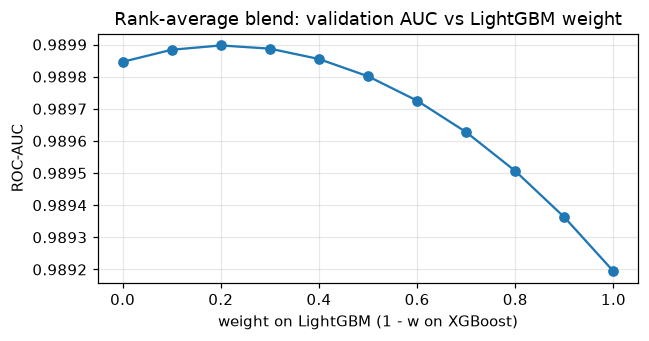

In [5]:
# --- Section 4: predictor comparison, hyperparameter search and ensemble -----
# Every model sees the SAME rows, features and time split. Validation AUC is the
# micro-averaged ROC-AUC over all unit-hours of the validation cases.
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

num_feats = [c for c in FEATS if c not in CAT_FEATURES]

# ---- 4.2a Physical baseline: the LP margin alone
RESULTS["LP margin alone (no learning)"] = dict(n_feats=1, val_auc=roc_auc_score(y_va, va["lp_margin"]), fit_s=0.0)

# ---- 4.2b Logistic regression (linear baseline): impute + scale numeric, one-hot categorical
t0 = time.time()
logreg = make_pipeline(
    ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_feats),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES)]),
    LogisticRegression(C=1.0, max_iter=300))
logreg.fit(tr[FEATS], y_tr)
PREDS["Logistic regression"] = logreg.predict_proba(va[FEATS])[:, 1]
RESULTS["Logistic regression"] = dict(n_feats=len(FEATS), val_auc=roc_auc_score(y_va, PREDS["Logistic regression"]),
                                      fit_s=time.time() - t0)

# ---- 4.2c Random forest (bagging ensemble of deep trees; sklearn handles NaN natively)
t0 = time.time()
rf = RandomForestClassifier(n_estimators=RF_TREES, min_samples_leaf=50, max_features="sqrt", max_samples=0.25,
                            n_jobs=N_JOBS, random_state=RANDOM_SEED)
rf.fit(tr[FEATS], y_tr)
PREDS["Random forest"] = rf.predict_proba(va[FEATS])[:, 1]
RESULTS["Random forest"] = dict(n_feats=len(FEATS), val_auc=roc_auc_score(y_va, PREDS["Random forest"]),
                                fit_s=time.time() - t0)
del rf, logreg; gc.collect()             # free RAM before the grid search

# ---- 4.2d XGBoost (same parameters as Short notebook 2, native categoricals)
def fit_xgb(feats, params=None):
    p = {**XGB_PARAMS, **(params or {})}
    t0 = time.time()
    Xtr, Xva = tr[feats].copy(), va[feats].copy()
    for c in [c for c in CAT_FEATURES if c in feats]:
        Xtr[c] = Xtr[c].astype("category")
        Xva[c] = pd.Categorical(Xva[c], categories=Xtr[c].cat.categories)
    dtr = xgb.DMatrix(Xtr, label=y_tr, enable_categorical=True)
    dva = xgb.DMatrix(Xva, label=y_va, enable_categorical=True)
    es = xgb.callback.EarlyStopping(rounds=100, save_best=True, maximize=True, data_name="valid", metric_name="auc")
    m = xgb.train(p, dtr, MAX_ROUNDS, evals=[(dva, "valid")], callbacks=[es], verbose_eval=False)
    pred = m.predict(dva)
    return m, pred, roc_auc_score(y_va, pred), time.time() - t0

m_xgb, p_xgb, auc_xgb, s_xgb = fit_xgb(FEATS)
PREDS["XGBoost"] = p_xgb
RESULTS["XGBoost"] = dict(n_feats=len(FEATS), val_auc=auc_xgb, fit_s=s_xgb, best_iter=m_xgb.best_iteration + 1)

order = ["LP margin alone (no learning)", "Logistic regression", "Random forest", "XGBoost", "LightGBM"]
cmp_table = pd.DataFrame(RESULTS).T.loc[order, ["n_feats", "val_auc", "fit_s", "best_iter"]]
cmp_table["val_auc"] = cmp_table["val_auc"].astype(float).round(5)
cmp_table["fit_s"] = cmp_table["fit_s"].astype(float).round(0)
print("4.2 Predictor comparison (identical data, every 4th training case):")
display(cmp_table)

# ---- 4.3 Hyperparameter search (grid, screened at learning_rate 0.1 to halve the cost;
#          the final models use 0.05 with early stopping, which only changes the number of rounds)
grid_rows = []
for nl in [63, 255, 511]:
    for mcs in [50, 200, 1000]:
        m, _, auc, sec = fit_lgb(FEATS, dict(num_leaves=nl, min_child_samples=mcs, learning_rate=0.1))
        grid_rows.append(dict(num_leaves=nl, min_child_samples=mcs, val_auc=auc, best_iter=m.best_iteration, fit_s=sec))
        del m; gc.collect()
grid_lgb = pd.DataFrame(grid_rows)
print("4.3 LightGBM grid (learning_rate=0.1, feature/bagging fraction 0.8):")
display(grid_lgb.pivot(index="num_leaves", columns="min_child_samples", values="val_auc").round(5))
grid_rows = []
for md in [6, 8, 10]:
    for mcw in [10, 50]:
        m, _, auc, sec = fit_xgb(FEATS, dict(max_depth=md, min_child_weight=mcw, learning_rate=0.1))
        grid_rows.append(dict(max_depth=md, min_child_weight=mcw, val_auc=auc, best_iter=m.best_iteration + 1, fit_s=sec))
        del m; gc.collect()
grid_xgb = pd.DataFrame(grid_rows)
print("4.3 XGBoost grid (learning_rate=0.1, subsample/colsample 0.8):")
display(grid_xgb.pivot(index="max_depth", columns="min_child_weight", values="val_auc").round(5))

# ---- 4.4 Ensemble: rank-average of model scores (ROC-AUC depends only on ranks)
R = {k: rankdata(PREDS[k]) / len(y_va) for k in ["LightGBM", "XGBoost", "Random forest", "Logistic regression"]}
print("Spearman correlation of validation predictions:")
display(pd.DataFrame(R).corr().round(4))
ws = np.round(np.arange(0, 1.01, 0.1), 1)
blend_curve = pd.Series([roc_auc_score(y_va, w * R["LightGBM"] + (1 - w) * R["XGBoost"]) for w in ws], index=ws)
ens_rows = [("LightGBM alone", RESULTS["LightGBM"]["val_auc"]),
            ("XGBoost alone", RESULTS["XGBoost"]["val_auc"]),
            ("LightGBM + XGBoost, equal-weight rank average", roc_auc_score(y_va, R["LightGBM"] + R["XGBoost"])),
            (f"LightGBM + XGBoost, best weight w_LGB={blend_curve.idxmax()}", blend_curve.max()),
            ("LightGBM + XGBoost + RF, equal-weight rank average",
             roc_auc_score(y_va, R["LightGBM"] + R["XGBoost"] + R["Random forest"]))]
ens_table = pd.DataFrame(ens_rows, columns=["model", "val_auc"]).round(5)
display(ens_table)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(blend_curve.index, blend_curve.values, marker="o")
ax.set(title="Rank-average blend: validation AUC vs LightGBM weight", xlabel="weight on LightGBM (1 - w on XGBoost)",
       ylabel="ROC-AUC")
plt.tight_layout(); plt.show()

## 5. Validation strategy

**Time-based split.** Both short notebooks validate on the last ~15 % of training cases by Run No: up to Run No 2483 for fitting and the rest (October 2021 to December 2022) for validation. This mirrors the actual task, where the model is trained on 2015–2022 and must predict 2023–2024. The validation score is used for early stopping and for all model and feature decisions; the final model is then refit on all training cases with the chosen number of rounds. The ON-rate priors are computed on the fitting part only, so no validation label leaks into a feature.

**Why not random K-fold.** Consecutive cases overlap by 144 of 168 hours and agree on 88 % of their labels (Section 2.3, H6). A randomly chosen validation case therefore almost always has its neighbours in the training set. We measured the effect with the same LightGBM model and data (output below):

| Split | Validation AUC |
|---|---|
| Random split of rows | 0.99977 |
| Random split of cases | 0.99314 |
| **Time split (ours)** | **0.98919** |

The random row split is almost perfect because the same unit-hour, with nearly the same inputs, appears in the neighbouring cases in the training set. Even a split by whole cases overestimates the AUC by 0.004. Both would make every model look better than it is and would reward memorising neighbours rather than generalising to a new period.

**Purge gap.** The first validation cases overlap the last training weeks. Dropping the validation cases within 7 or 14 days of the split changes the AUC by at most 0.00014 (0.98919 → 0.98905 / 0.98912), so leakage across the single split boundary is negligible.

**Stability.** The validation period is hard: it covers the 2022 energy crisis, and the validation ON-rate is only 0.355 against 0.548 in training. The AUC is 0.975–0.996 in every quarter (Fig. 5.1), lowest in 2022 Q2. Per unit, it ranges from 0.954 (Haukeli) to 0.999 (Byrte). The pooled AUC is higher than most per-unit values, because micro-averaging also rewards ranking units against each other.

**Public vs private leaderboard.** The brief warns of a gap between the public and private leaderboard. We therefore select our final submissions on the time-split validation score, not on public rank. The covariate-shift check in Short notebook 2 (Section 4b there) shows that no feature shifts by more than 1 training standard deviation between training and test, and for every feature at most 1 % of test rows fall outside the training range. Our most important features are relative (price rank, LP margins), which are robust to the change in price level between 2022 and 2023–2024. `[TODO: compare the validation AUC with the public LB score once known]`

,split,val_auc
0,Random split of rows,0.99977
1,Random split of cases,0.99314
2,Time split (ours): last ~15 % of Run No,0.98919


Validation AUC with a  0-day purge gap: 0.98919  (110 cases)
Validation AUC with a  7-day purge gap: 0.98905  (108 cases)
Validation AUC with a 14-day purge gap: 0.98912  (106 cases)


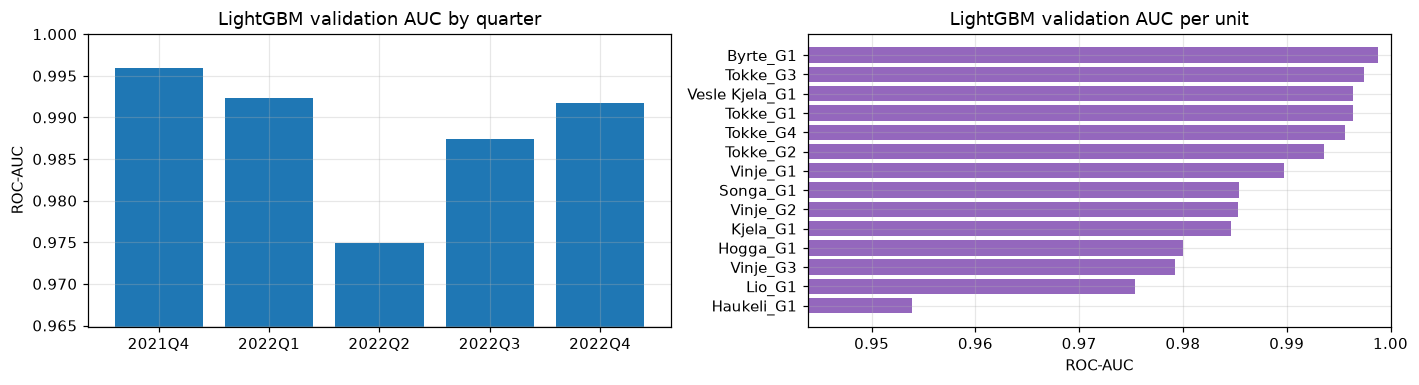

Note: per-unit AUCs are lower than the pooled AUC because pooling also rewards
ranking units against each other (e.g. a mostly-ON unit vs a mostly-OFF unit).


In [6]:
# --- Section 5: validation strategy -------------------------------------------
# (a) why random splits are misleading here, (b) effect of a purge gap at the
# split boundary, (c) stability of the time-split score inside the validation period.

# (a) Random row-level split vs case-level random split vs time split, same model and data.
rng = np.random.default_rng(RANDOM_SEED)
rows = []
mask_row = rng.random(len(long)) < 0.15
cases = long["Run No"].unique()
va_cases = rng.choice(cases, size=int(0.15 * len(cases)), replace=False)
mask_case = long["Run No"].isin(va_cases).to_numpy()
for name, mask in [("Random split of rows", mask_row), ("Random split of cases", mask_case)]:
    a, b = long[~mask].copy(), long[mask].copy()
    add_on_rate_priors(a, b)
    _, _, auc, _ = fit_lgb(FEATS, train=a, valid=b)
    rows.append(dict(split=name, val_auc=auc))
    del a, b; gc.collect()
rows.append(dict(split="Time split (ours): last ~15 % of Run No", val_auc=RESULTS["LightGBM"]["val_auc"]))
split_table = pd.DataFrame(rows).round(5)
display(split_table)

# (b) Purge gap: drop validation cases whose week overlaps the training period.
va_run = va["Run No"].to_numpy()
for gap in [0, 7, 14]:
    keep = va_run > CUT + gap
    print(f"Validation AUC with a {gap:>2}-day purge gap: {roc_auc_score(y_va[keep], p_lgb[keep]):.5f}  "
          f"({np.unique(va_run[keep]).size} cases)")

# (c) Stability over the validation period (by quarter) and per unit.
vq = va["start"].dt.to_period("Q").astype(str).to_numpy()
by_q = pd.Series({q: roc_auc_score(y_va[vq == q], p_lgb[vq == q]) for q in np.unique(vq)})
by_unit = pd.Series({u: roc_auc_score(y_va[va["unit"].to_numpy() == u], p_lgb[va["unit"].to_numpy() == u])
                     for u in va["unit"].unique()}).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(by_q.index, by_q.values); ax[0].set_ylim(by_q.min() - 0.01, 1)
ax[0].set(title="LightGBM validation AUC by quarter", ylabel="ROC-AUC")
ax[1].barh(by_unit.index, by_unit.values, color="tab:purple"); ax[1].set_xlim(by_unit.min() - 0.01, 1)
ax[1].set(title="LightGBM validation AUC per unit", xlabel="ROC-AUC")
plt.tight_layout(); plt.show()
print("Note: per-unit AUCs are lower than the pooled AUC because pooling also rewards\n"
      "ranking units against each other (e.g. a mostly-ON unit vs a mostly-OFF unit).")

## 6. Model Interpretation  *(avoids −3)*

We interpret the LightGBM model from Section 4 (all 81 features) with three methods: gain importance, SHAP values and partial dependence. For comparison we also show the model trained **without** the LP features. Figures follow the code cell below.

### 6.1 Gain importance (Fig. 6.1)
- The LP features account for **74 % of the total gain**. `lp_unit_load` alone has 47 %, followed by `lp_margin_ctr5`, `lp_qfrac`, `lp_hours_pos_frac` and `lp_margin`. The fifth most important feature is `unit_id`, which captures each unit's base rate and SHOP's preference order among identical units (Section 2.2).
- **Without the LP features**, the water-value, storage and inflow group takes over (about 75 % of gain). The top features are then `price_wv_ratio`, `pwv_spread_end`, `unit_id`, `down_wv_end` and `rank_above_cut`. All of these are our hand-made versions of the price-vs-water-value rule from Section 1.3. So the model without LP rebuilds the same economic reasoning from simpler features, less precisely; the LP does this reasoning per case and hands the model the result.

### 6.2 SHAP (Fig. 6.2)
SHAP values show each feature's contribution to the log-odds of ON for 5000 validation rows.
- A **positive LP margin** (price above the LP's marginal water cost, red) pushes the prediction strongly towards ON (up to +4 log-odds), and a negative margin pushes it towards OFF. The same holds for the centred 5-hour margin and the margins of the neighbouring hours (`lp_margin_lag1`, `lp_margin_lead1`). The model uses those to bridge short dips, which matches the block structure of real schedules (start costs).
- `lp_hours_pos_frac` (the share of the week in which the plant is economic) and `lp_unit_load` (whether the LP's discharge reaches this unit) separate units that run most of the week from units that run only in the peaks.
- `price_minus_mean`: hours priced above the week's mean push towards ON, which is H1 again.
- `unit_id` has a wide spread in both directions: the same inputs mean different things for different units.

### 6.3 Partial dependence (Fig. 6.3)
Partial dependence shows the mean predicted P(ON) when one feature is set to a value for all rows.
- **`lp_margin`:** a sharp step at zero, from P(ON) ≈ 0.28 to ≈ 0.44. The model has learned the economic rule "run when the price is above the water value" through the LP.
- **`price_rank`:** P(ON) rises steadily with the hour's rank in the week in both models, much more strongly without the LP (0.320 → 0.341). With the LP, most of that information is already in the LP margin.
- **`fill_frac`:** without the LP, P(ON) rises for full reservoirs (spill avoidance, H3); with the LP it is nearly flat, because the LP already includes the reservoir balance.
- **`pwv_spread_net`:** in the full model P(ON) rises at a spread of zero, as expected. In the model without LP the curve slopes slightly *downward* above zero. Two things explain this. First, that model takes the main price-vs-water-value effect from related features (`price_wv_ratio`, `pwv_spread_end`; Spearman ρ ≈ 0.4 with `pwv_spread_net`), so `pwv_spread_net` only adds a small correction on top. Second, 89 % of the hours with spreads above 100 EUR/MWh are from the 2021–2022 crisis, when the ON-rate at such spreads was only 0.40–0.51, the same drop as in Fig. 2.3 (middle). Partial dependence shows what the model does, not a causal effect, and with several related features each single curve is small (≤ 0.003 here).

**Summary.** All three methods agree: the model has learned SHOP's economic logic of running when the price is above the water value, in the most expensive hours of the week and in continuous blocks, and it gets this mostly from the LP relaxation of SHOP's own problem. The remaining errors sit in the marginal hours. The weakest unit is Haukeli (AUC 0.954, Section 5); its intake reservoir Vatjern is one of the two reservoirs whose volume is a filled-in constant (Section 2.1), so the model cannot see its real storage state.

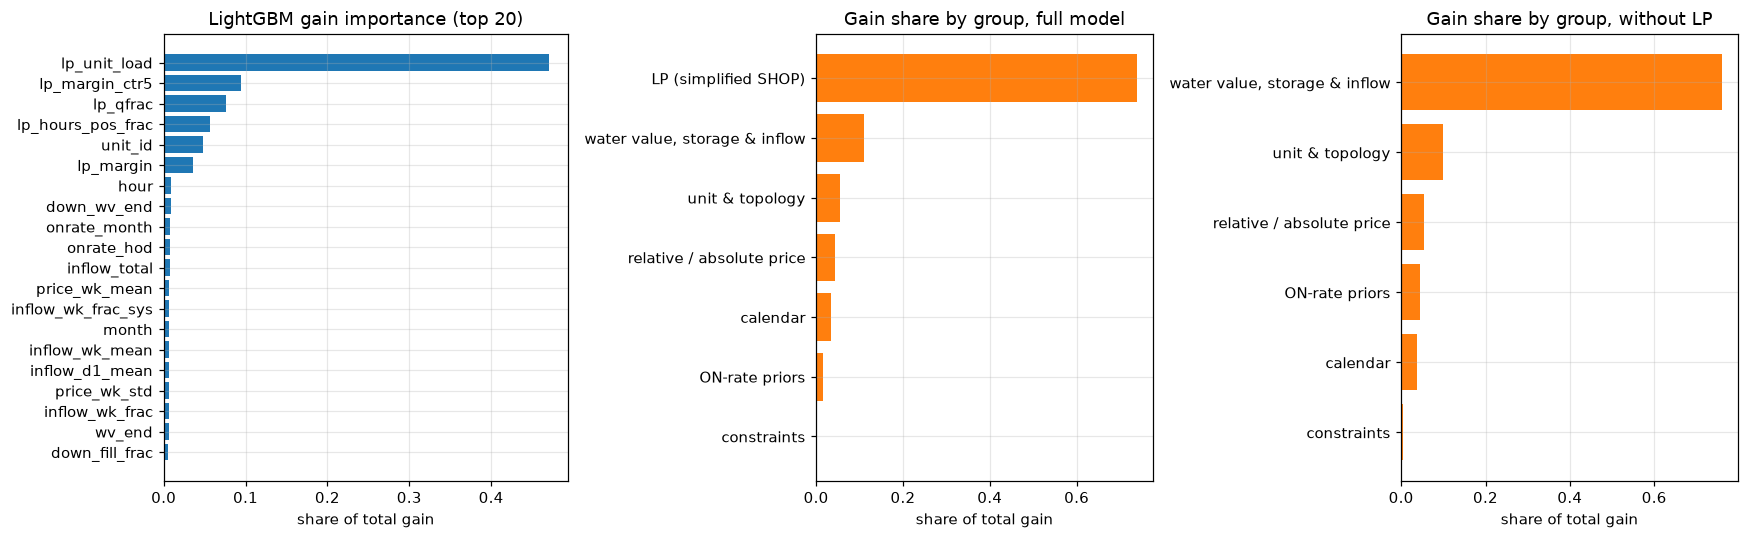

Top 10 features without LP features: price_wv_ratio, pwv_spread_end, unit_id, down_wv_end, rank_above_cut, onrate_month, wv_net, wv_sys_mean, inflow_wk_frac, fill_plus_inflow


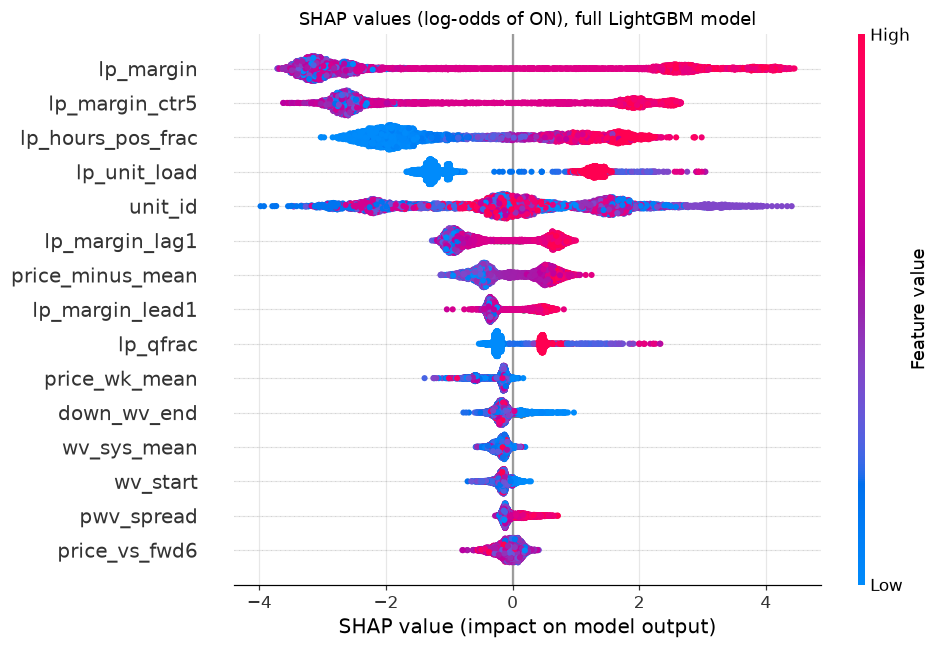

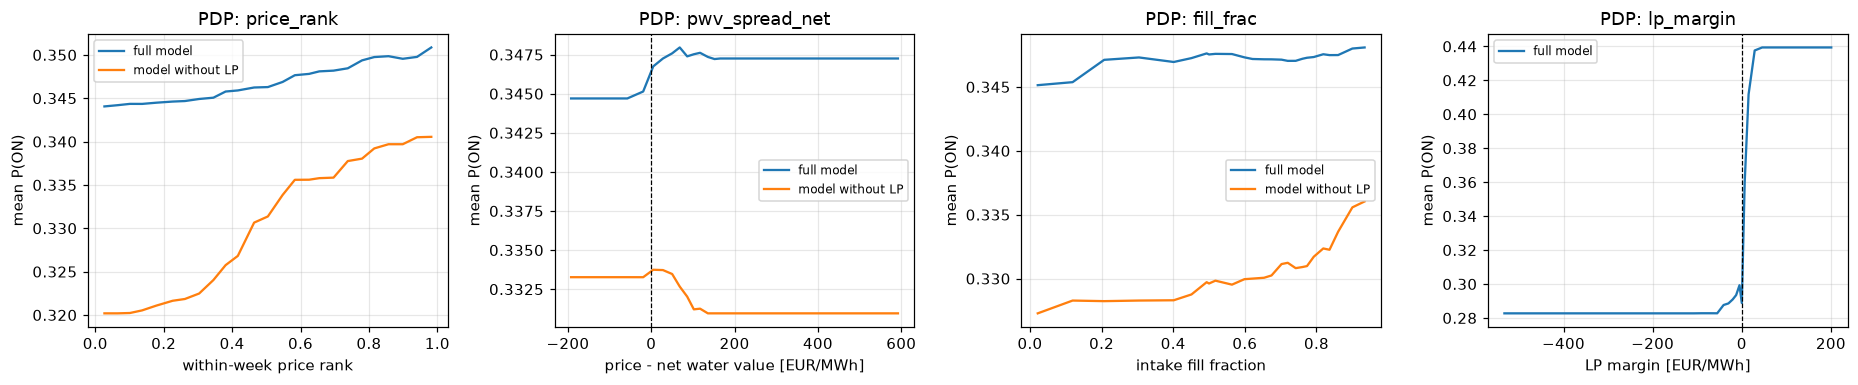

In [7]:
# --- Section 6: model interpretation ------------------------------------------
# (a) gain importance, per feature and per feature group; (b) SHAP on a sample of
# validation rows; (c) partial dependence for the economic features, for the
# full model and for the model trained without LP features.
import shap

def group_of(f):
    if f.startswith("lp_"): return "LP (simplified SHOP)"
    if f.startswith(("onrate_",)): return "ON-rate priors"
    if f.startswith(("minflow_", "minvol_")): return "constraints"
    if f in ("unit_id", "plant_id", "p_min", "p_max", "p_nom", "startcost", "n_units_at_plant", "max_vol"): return "unit & topology"
    if f in ("hour", "hour_of_day", "dow", "month", "hour_in_horizon", "day_in_case") or f.endswith(("_sin", "_cos")): return "calendar"
    if f.startswith("price") and "wv" not in f: return "relative / absolute price"
    return "water value, storage & inflow"

imp = pd.DataFrame({"feature": FEATS, "gain": m_lgb.feature_importance("gain")})
imp["share"] = imp["gain"] / imp["gain"].sum()
imp["group"] = imp["feature"].map(group_of)
imp_nolp = pd.DataFrame({"feature": FEATS_NOLP, "gain": m_nolp.feature_importance("gain")})
imp_nolp["share"] = imp_nolp["gain"] / imp_nolp["gain"].sum()
imp_nolp["group"] = imp_nolp["feature"].map(group_of)

fig, ax = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.2, 1, 1]})
top = imp.nlargest(20, "share").iloc[::-1]
ax[0].barh(top["feature"], top["share"]); ax[0].set(title="LightGBM gain importance (top 20)", xlabel="share of total gain")
for a, d, t in [(ax[1], imp, "Gain share by group, full model"), (ax[2], imp_nolp, "Gain share by group, without LP")]:
    gs = d.groupby("group")["share"].sum().sort_values()
    a.barh(gs.index, gs.values, color="tab:orange"); a.set(title=t, xlabel="share of total gain")
plt.tight_layout(); plt.show()
print("Top 10 features without LP features:", ", ".join(imp_nolp.nlargest(10, "share")["feature"]))

# (b) SHAP (TreeExplainer, exact for trees) on 5,000 random validation rows
Xs = va[FEATS].sample(min(5000, len(va)), random_state=RANDOM_SEED)
sv = shap.TreeExplainer(m_lgb).shap_values(Xs)
sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, Xs, max_display=15, show=False, plot_size=(9, 6))
plt.title("SHAP values (log-odds of ON), full LightGBM model"); plt.tight_layout(); plt.show()

# (c) Partial dependence: average prediction when one feature is set to each grid value
def pdp(model, feats, X, col, n=25):
    grid = np.unique(np.nanquantile(X[col], np.linspace(0.02, 0.98, n)))
    out = []
    for g in grid:
        Z = X[feats].copy(); Z[col] = g
        out.append(model.predict(Z, num_iteration=model.best_iteration).mean())
    return grid, np.array(out)

Xp = va.sample(min(4000, len(va)), random_state=RANDOM_SEED)
pd_feats = [("price_rank", "within-week price rank"), ("pwv_spread_net", "price - net water value [EUR/MWh]"),
            ("fill_frac", "intake fill fraction"), ("lp_margin", "LP margin [EUR/MWh]")]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, (col, lab) in zip(ax, pd_feats):
    g, y = pdp(m_lgb, FEATS, Xp, col); a.plot(g, y, label="full model")
    if col in FEATS_NOLP:
        g2, y2 = pdp(m_nolp, FEATS_NOLP, Xp, col); a.plot(g2, y2, label="model without LP")
    a.set(title=f"PDP: {col}", xlabel=lab, ylabel="mean P(ON)"); a.legend(fontsize=8)
    if col in ("pwv_spread_net", "lp_margin"): a.axvline(0, color="k", lw=0.8, ls="--")
plt.tight_layout(); plt.show()

## 7. Results & leaderboard

### 7.1 Kaggle
| Submission | Notebook | Validation AUC | Public LB | Private LB | Selected |
|---|---|---|---|---|---|
| LightGBM, 81 features | Short notebook 1 | 0.98977 | `[TODO]` | `[TODO]` | `[TODO]` |
| XGBoost, 83 features | Short notebook 2 | 0.99092 | `[TODO]` | `[TODO]` | `[TODO]` |
| `[TODO: earlier submissions worth listing, e.g. the model before the LP features]` | | ≈ 0.96 | `[TODO]` | `[TODO]` | |

Virtual Teams beaten: `[TODO]`.

### 7.2 All experiments
The table below (output after this section) collects all validation scores from this report. The rows on the report subset use identical data and can be compared directly; the short-notebook rows use all training cases.

The main results:
1. **Features matter more than the learner.** The LP features add 0.029 AUC (0.960 → 0.989). Switching between LightGBM and XGBoost changes the AUC by less than 0.001, and tuning hyperparameters by less than 0.001.
2. **Gradient boosting is the best model family** (≈ 0.989–0.990), ahead of random forest (0.986) and logistic regression (0.955).
3. **Ensembling does not help** here (+0.00005 at best), because the two boosting models make the same errors.
4. **Honest validation matters.** A random split would have reported 0.9998 instead of 0.989.

In [8]:
# --- Section 7: results summary -------------------------------------------------
# (a) report experiments (every 4th case, identical data); (b) the short notebooks,
# trained on ALL 2922 training cases (numbers copied from their saved outputs).
summary = pd.concat([
    cmp_table[["n_feats", "val_auc"]].assign(data="report subset (731 cases)"),
    ens_table.set_index("model")[["val_auc"]].iloc[2:].assign(n_feats=np.nan, data="report subset (731 cases)"),
    pd.DataFrame({"n_feats": [81, 83], "val_auc": [0.98977, 0.99092], "data": "full training set (2922 cases)"},
                 index=["Short notebook 1: LightGBM", "Short notebook 2: XGBoost (+2 LP features)"]),
])
summary.index.name = "model"
display(summary[["data", "n_feats", "val_auc"]])

,data,n_feats,val_auc
model,,,
LP margin alone (no learning),report subset (731 cases),1.0,0.95960
Logistic regression,report subset (731 cases),81.0,0.95462
Random forest,report subset (731 cases),81.0,0.98637
XGBoost,report subset (731 cases),81.0,0.98985
LightGBM,report subset (731 cases),81.0,0.98919
"LightGBM + XGBoost, equal-weight rank average",report subset (731 cases),NaN,0.98980
"LightGBM + XGBoost, best weight w_LGB=0.2",report subset (731 cases),NaN,0.98990
"LightGBM + XGBoost + RF, equal-weight rank average",report subset (731 cases),NaN,0.98951
Short notebook 1: LightGBM,full training set (2922 cases),81.0,0.98977


## 8. Conclusion, limitations & reproducibility

### 8.1 What worked
- **Using the structure of the problem.** The labels come from an optimiser, so the most useful feature was a simplified version of that optimiser: a per-case LP relaxation of SHOP's weekly problem, built from the topology file. Alone it gives AUC 0.956, and with it the model reaches about 0.99.
- **Domain-driven features before the LP**: relative price within the week, price vs. water value, reservoir fill and inflow. These took us from the ON-rate priors to about 0.96, and the interpretation (Section 6) shows the model uses them in line with the economics.
- **One long-table model** for all units, with a unit-id feature and leak-free priors.
- **Time-based validation**, which turned out to matter (Section 5).

### 8.2 What did not work (negative results)
- **Model ensembles** of LightGBM, XGBoost and random forest: no measurable gain (Section 4.4).
- **Hyperparameter tuning**: flat within seed noise (Section 4.3).
- **Extra feature groups** before the LP (end-of-week volume, daily release, block features, unit order): within seed noise (Section 3.3).
- **Feature selection** by near-constant and correlation filters: same AUC with 15 fewer features, so we kept the full set.
- **Logistic regression** did worse than its own LP-margin input.

### 8.3 Limitations
- **The LP is a relaxation.** It ignores the ON/OFF integers, start costs, `p_min` and head-dependent efficiency. The remaining errors are in the marginal hours where these matter. Short notebook 2's integer-rounding and water-value-robustness features target exactly this.
- **Identical units are partly interchangeable.** Which of Tokke G1–G4 or Vinje G1–G3 SHOP starts is partly arbitrary, which limits per-unit accuracy.
- **Data limits.** The water values are synthetic, and the Hyljelihyl and Vatjern volumes are constants, which hurts Haukeli in particular (AUC 0.954).
- **Report experiments use a subset** (every 4th case) to keep the many comparisons affordable. The short notebooks use all data, and their scores are consistent with the subset results.
- **A predicted schedule is not a feasible schedule.** We predict hour-by-hour probabilities, which can break minimum-load or start constraints. To be used in practice, as SINTEF's InterOpt project intends, the predictions would warm-start or constrain SHOP rather than replace it.

### 8.4 Reproducibility
- *Short notebook 1* reproduces the LightGBM submission, and *Short notebook 2* the XGBoost submission. `[TODO: state which one gives our best Kaggle score]` Both start from the raw data in `DATA_DIR`, run offline with fixed seeds and finish within the 12 h / 4-core / 32 GB budget (the LP takes about 6 min in Short notebook 1 and about 21 min in Short notebook 2, which solves three scenarios per case).
- This report runs the same feature code. Its experiments use a cached feature table (`artifacts/report_long_step4.pkl`), which the setup cell rebuilds from Short notebook 1 if it is missing. The environment is listed below.

In [9]:
# --- Section 8: environment used for all saved outputs -----------------------
import sys, platform, sklearn, scipy, shap, matplotlib
print("Python", sys.version.split()[0], "|", platform.platform())
for mod in (np, pd, sklearn, scipy, lgb, xgb, shap, matplotlib):
    print(f"  {mod.__name__:<12} {mod.__version__}")

Python 3.13.8 | Windows-11-10.0.26200-SP0
  numpy        2.5.4
  pandas       3.1.0
  sklearn      1.9.1
  scipy        1.18.1
  lightgbm     4.7.0
  xgboost      3.4.1
  shap         0.54.1
  matplotlib   3.11.2
